# Content-based recommender and new products

**Owner:** Member 4 (Content-Based & New Products), Karim Samaan · **Branch:** `m4-content` · **Code:** `src/hm_recsys/content.py`, tests in `tests/test_content.py`

*Claude was used to help write code and commentary.*

Members 2 and 3 recommend from purchase data: what sells, and what similar customers bought. Both go quiet in two places. A customer with one or two purchases gives collaborative filtering almost nothing to learn from, and a product launched this week has no sales at all, so neither popularity nor CF can rank it. Every article does come with a written description and a set of attributes, though. This notebook builds a recommender on those, and checks where it actually earns its place in the hybrid.

## Questions this notebook answers

1. **How should a product become text, and which text representation works best?** Bag of Words, TF-IDF, TF-IDF on lemmas and sentence-BERT, judged by which products they call "similar" and by what customers bought next.
2. **How much should recent purchases count?** Customer profiles with different recency half-lives.
3. **Does content beat "trending now"?** Overall and for light customers, on the same test week and with the same `evaluate()` as everyone else.
4. **Can we sell brand-new products?** A personal "new in for you" row, and launch audiences for marketing.
5. **Are the lists too samey?** The "all black T-shirts" problem, measured.

## Checklist
- [x] Build item text (description + attributes)
- [x] BoW vs TF-IDF (optional lemmatisation)
- [x] Recency-weighted customer profiles
- [x] Score overall, on light customers, and on new items
- [x] Diversity and novelty of content-based lists
- [x] Optional: sentence-BERT vs TF-IDF

Runtime: about 40 minutes on a two-core laptop, most of it the validation grid. The sentence-BERT vectors take another 35 minutes the first time and are cached after that (section 3).

In [1]:
%load_ext autoreload
%autoreload 2

import gc
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hm_recsys.baselines import (
    AgeBandPopularityRecommender, BuyAgainRecommender, NewCustomerRecommender,
    PopularityRecommender, RandomRecommender,
)
from hm_recsys.collaborative import ALSRecommender
from hm_recsys.content import (
    AttributePopularityRecommender, ContentBasedRecommender, build_item_text,
    lemmatize, sentence_embeddings, vectorize,
)
from hm_recsys.data import PROCESSED_DIR, RAW_DIR, assign_segments, load_split, new_items
from hm_recsys.evaluation import evaluate

FIG_DIR = Path("../reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORTS = Path("../reports")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 70)
SEED = 42
TREND_WEEKS = 2   # Member 2's validated "trending now" window

## 1. Data

Same files as everyone else: Member 1's time-based split (`load_split`, 12 weeks of training, then one test week) plus the full article table, which is where the descriptions live. Customer ages are only used by the fallback for customers with no purchases (Member 2's new-customer path).

"Launches" here means articles that sell in the test week but never sold in training, the same definition as `new_items()` in `data.py`.

In [2]:
train, test = load_split()
for df in (train, test):
    df["t_dat"] = pd.to_datetime(df["t_dat"])
    df["customer_id"] = df["customer_id"].astype(str)
articles = pd.read_csv(RAW_DIR / "articles.csv", dtype={"article_id": "int64"})
customers = pd.read_csv(RAW_DIR / "customers.csv", usecols=["customer_id", "age"])
info = articles.set_index("article_id")

test_customers = pd.Series(test["customer_id"].unique())
segments = assign_segments(train, test_customers)
segments.index = test_customers
launches = sorted(new_items(train, test))

print(f"train: {len(train):,} rows, {train['t_dat'].min():%d %b} to {train['t_dat'].max():%d %b %Y}")
print(f"test : {len(test):,} rows, {len(test_customers):,} customers")
print(segments.value_counts().to_string())
print(f"\ncatalogue: {len(articles):,} articles, {articles['product_code'].nunique():,} products "
      f"(colour variants share a product_code)")
print(f"articles without a description: {articles['detail_desc'].isna().sum():,}")
is_launch = test["article_id"].isin(launches)
print(f"\nlaunches (sold in the test week, never in train): {len(launches):,}")
print(f"  share of test purchases: {is_launch.mean():.2%}")
print(f"  test customers who bought at least one: "
      f"{test.loc[is_launch, 'customer_id'].nunique():,} "
      f"({test.loc[is_launch, 'customer_id'].nunique() / len(test_customers):.1%})")
sold_codes = set(info.loc[info.index.intersection(train["article_id"].unique()), "product_code"])
launch_codes = info.loc[launches, "product_code"]
print(f"  new colour or version of a product that already sells: {launch_codes.isin(sold_codes).mean():.0%}")
print(f"  product code never sold in the 12 training weeks: {(~launch_codes.isin(sold_codes)).mean():.0%}")

train: 3,664,080 rows, 24 Jun to 15 Sep 2020
test : 240,311 rows, 68,984 customers
segment
regular    33168
new        19765
light      16051

catalogue: 105,542 articles, 47,224 products (colour variants share a product_code)
articles without a description: 416

launches (sold in the test week, never in train): 922
  share of test purchases: 4.12%
  test customers who bought at least one: 6,134 (8.9%)
  new colour or version of a product that already sells: 48%
  product code never sold in the 12 training weeks: 52%


## 2. Turning a product into text

`build_item_text` joins three things for each article:

- the **product name** (`prod_name`),
- the **attributes** that describe what the product is: type, group, pattern, colour (three versions of it), department, index, section and garment group,
- the **written description** (`detail_desc`).

Codes and numeric ids are left out because they repeat the names. Placeholder values like "Unknown" or "undefined" are dropped, otherwise two products would look alike just because both are missing a field.

Two examples below are colour variants of the same product. They share a `product_code` and almost all of their text, so any text model will call them near-identical. That matters later: it's the root of the "same T-shirt in five colours" risk.

In [3]:
texts = build_item_text(articles)
variant_counts = info.groupby("product_code").size()
best_seller = next(a for a in PopularityRecommender(weeks=1).fit(train).ranking_
                   if variant_counts[info.loc[a, "product_code"]] > 1)
code_ = info.loc[best_seller, "product_code"]
variant = info.index[(info["product_code"] == code_) & (info.index != best_seller)][:1].tolist()
other = info.index[info["product_group_name"] == "Swimwear"][:1].tolist()
for a in [best_seller, *variant, *other]:
    print(f"{a}: {texts[a]}\n")

words = texts.str.split().str.len()
print(f"words per article: median {words.median():.0f}, 90th percentile {words.quantile(.9):.0f}")
print(f"distinct texts: {texts.nunique():,} for {len(texts):,} articles")

865799006: Pink HW barrel. Trousers Garment Lower body Solid Light Beige Dusty Light Beige Trouser Ladieswear Ladieswear Womens Everyday Collection Trousers. 5-pocket, ankle-length trousers in washed cotton twill with a high waist and wide, tapered legs with decorative seams at the hems.

865799001: Pink woven. Trousers Garment Lower body Solid Light Beige Dusty Light Beige Trouser Ladieswear Ladieswear Womens Everyday Collection Trousers. 5-pocket, ankle-length trousers in washed cotton twill with a high waist and wide, tapered legs with decorative seams at the hems.

184121021: FIFTY SHADES moulded halternec. Bikini top Swimwear All over pattern White Light White Swimwear Lingeries/Tights Ladieswear Womens Swimwear, beachwear Swimwear. Bikini top with underwired, moulded, lightly padded cups, a metal fastener at the back, ties at the back of the neck and a bow at the front.



words per article: median 43, 90th percentile 60
distinct texts: 100,094 for 105,542 articles


## 3. From text to vectors

Four representations, from simplest to most "semantic":

| Representation | What it does | Why try it |
|---|---|---|
| **Bag of Words** | counts each word (English stop words removed, words in fewer than 2 articles dropped) | the simplest baseline |
| **TF-IDF** | same counts, but words that appear in many articles ("garment", "ladieswear") weigh less and rare, specific ones ("broderie", "lyocell") weigh more | stops generic words dominating similarity |
| **TF-IDF + lemmas** | TF-IDF after spaCy lemmatisation, so "pockets" and "pocket" are one word | descriptions are short, so merging word forms could matter |
| **Sentence-BERT** | a small transformer (all-MiniLM-L6-v2) reads the whole text and returns one 384-number vector | catches meaning that word counts miss ("cropped" vs "short") |

All vectors are scaled to length 1, so the dot product of two products is their cosine similarity.

In [4]:
t0 = time.time()
lemma_texts = lemmatize(texts)
print(f"lemmatised {texts.nunique():,} distinct texts in {time.time() - t0:.0f}s")
print("before:", texts[best_seller][:110])
print("after :", lemma_texts[best_seller][:110])

reps = {}
reps["BoW"], bow_vec = vectorize(texts, "bow")
reps["TF-IDF"], tfidf_vec = vectorize(texts, "tfidf")
reps["TF-IDF + lemmas"], _ = vectorize(lemma_texts, "tfidf")
for name, X in reps.items():
    print(f"{name:<16} vocabulary {X.shape[1]:>6,} words, {X.nnz / X.shape[0]:.0f} non-zero per article")

lemmatised 100,094 distinct texts in 209s
before: Pink HW barrel. Trousers Garment Lower body Solid Light Beige Dusty Light Beige Trouser Ladieswear Ladieswear 
after : pink hw barrel trouser garment lower body solid light beige dusty light beige trouser ladieswear ladieswear wo


BoW              vocabulary 11,190 words, 28 non-zero per article
TF-IDF           vocabulary 11,190 words, 28 non-zero per article
TF-IDF + lemmas  vocabulary 10,159 words, 27 non-zero per article


### Sentence-BERT (optional extension)

The model is the ONNX export of all-MiniLM-L6-v2 (Xenova/all-MiniLM-L6-v2 on Hugging Face), so it runs on a laptop CPU without PyTorch. `model.onnx` and `tokenizer.json` go in `data/raw/all-MiniLM-L6-v2/`, which git ignores like the rest of the data. Its tokenizer is the standard lower-cased BERT WordPiece vocabulary (30,522 tokens); if Hugging Face only gives you `vocab.txt`, `tokenizers.BertWordPieceTokenizer(vocab, lowercase=True).save("tokenizer.json")` rebuilds an identical one.

Embedding 100,000 distinct texts takes about 40 minutes on two CPU cores, so the vectors are cached in `data/processed/` and later runs just load them. Without the model files the notebook skips this comparison and everything else still runs.

In [5]:
SBERT_DIR = RAW_DIR / "all-MiniLM-L6-v2"     # model.onnx + tokenizer.json (not in git, like the data)
SBERT_CACHE = PROCESSED_DIR / "sbert_minilm.parquet"
sbert = None
if SBERT_CACHE.exists():
    sbert = pd.read_parquet(SBERT_CACHE)
    sbert.index = sbert.index.astype("int64")
elif (SBERT_DIR / "model.onnx").exists():
    t0 = time.time()
    sbert = sentence_embeddings(texts, SBERT_DIR)
    sbert.columns = sbert.columns.astype(str)
    sbert.to_parquet(SBERT_CACHE)
    print(f"embedded {texts.nunique():,} distinct texts in {time.time() - t0:.0f}s")
if sbert is not None:
    reps["Sentence-BERT"] = sbert.reindex(texts.index).to_numpy(dtype=np.float32)
    print("sentence-BERT vectors:", reps["Sentence-BERT"].shape)
else:
    print("No sentence-BERT model found in ../models; this comparison is skipped.")

sentence-BERT vectors: (105542, 384)


### 3.1 Which products does each method call "similar"?

Before any customer is involved, a sanity check. For 1,000 products that sold in the last two weeks, I take the 10 nearest neighbours under each representation and count how often a neighbour shares the product's type, colour or department, and how often it's literally the same product in another colour. Random pairs give the reference point.

In [6]:
def nearest(X, rows, k=10, chunk=250):
    """The k most similar articles (by row position) for each row in ``rows``, excluding itself."""
    out = []
    for s in range(0, len(rows), chunk):
        r = rows[s:s + chunk]
        S = X[r] @ X.T
        S = S.toarray() if hasattr(S, "toarray") else np.asarray(S)
        S[np.arange(len(r)), r] = -np.inf
        top = np.argpartition(-S, k, axis=1)[:, :k]
        order = np.take_along_axis(S, top, axis=1).argsort(axis=1)[:, ::-1]
        out.append(np.take_along_axis(top, order, axis=1))
    return np.vstack(out)

recent_items = PopularityRecommender(weeks=TREND_WEEKS).fit(train).recent_
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(recent_items, size=min(1000, len(recent_items)), replace=False)
rows = texts.index.get_indexer(sample_ids)
attrs = {"same product, other colour": "product_code", "same product type": "product_type_name",
         "same colour": "colour_group_name", "same department": "department_name"}
ref = info.reindex(texts.index)

agree = {}
for name, X in reps.items():
    nb = nearest(X, rows)
    agree[name] = {label: (ref[col].to_numpy()[nb] == ref[col].to_numpy()[rows][:, None]).mean()
                   for label, col in attrs.items()}
random_pairs = {label: (ref[col].to_numpy()[rng.integers(len(ref), size=10_000)] ==
                        ref[col].to_numpy()[rng.integers(len(ref), size=10_000)]).mean()
                for label, col in attrs.items()}
agree["random pairs"] = random_pairs
neighbour_table = pd.DataFrame(agree).T
neighbour_table

,"same product, other colour",same product type,same colour,same department
BoW,0.2803,0.9164,0.5492,0.8931
TF-IDF,0.3421,0.8981,0.3322,0.8724
TF-IDF + lemmas,0.3373,0.8960,0.3506,0.8740
Sentence-BERT,0.3263,0.9041,0.3003,0.8425
random pairs,0.0001,0.0474,0.0807,0.0127


In [7]:
show_cols = ["prod_name", "product_type_name", "colour_group_name", "department_name"]
query = texts.index.get_indexer([best_seller])
print("query:", info.loc[texts.index[query[0]], show_cols].to_dict())
examples = {}
for name in ["BoW", "TF-IDF", *(["Sentence-BERT"] if "Sentence-BERT" in reps else [])]:
    nb = nearest(reps[name], query, k=5)[0]
    examples[name] = info.loc[texts.index[nb], show_cols].reset_index(drop=True)
del reps, nb   # the comparison matrices are not needed any more; the notebook is memory-hungry
gc.collect()
pd.concat(examples, axis=1)

query: {'prod_name': 'Pink HW barrel', 'product_type_name': 'Trousers', 'colour_group_name': 'Light Beige', 'department_name': 'Trouser'}


BoW                                                      \
        prod_name product_type_name colour_group_name department_name   
0      Pink woven          Trousers       Light Beige         Trouser   
1  Pink HW barrel          Trousers        Light Grey         Trouser   
2      Pink woven          Trousers             White         Trouser   
3      Pink woven          Trousers        Light Blue         Trouser   
4  ED Pink HW trs          Trousers       Light Beige   Woven bottoms   

           TF-IDF                                                      \
        prod_name product_type_name colour_group_name department_name   
0  Pink HW barrel          Trousers        Light Grey         Trouser   
1      Pink woven          Trousers       Light Beige         Trouser   
2      Pink woven          Trousers             White         Trouser   
3      Pink woven          Trousers        Light Blue         Trouser   
4  ED Pink HW trs          Trousers       Light Beige   Woven bottoms   

                 Sentence-BERT                                      \
                     prod_name product_type_name colour_group_name   
0               Pink HW barrel          Trousers        Light Grey   
1         Pink HW barrel denim          Trousers         Dark Grey   
2         Pink HW barrel denim          Trousers         Dark Blue   
3  Pink HW barrell leg trouser          Trousers        Light Blue   
4                  Woodland HW          Trousers          Dark Red   

                   
  department_name  
0         Trouser  
1         Trouser  
2         Trouser  
3         Trouser  
4         Trouser

**Reading this.** Every method puts products of the same type next to each other about 90% of the time (random pairs: under 5%), and mostly from the same department. So the text carries real product meaning. The differences are in what else each method latches onto:

- **Bag of Words leans on colour.** The colour appears three times in the attribute text (colour group, perceived colour, colour family), and raw counts reward that repetition, so 55% of BoW neighbours share the colour. TF-IDF knows words like "black" or "beige" appear in thousands of articles and gives them little weight, which drops that to a third.
- **About a third of every method's neighbours are the same product in another colour.** Variants share a name and a description, so they're the closest match by any text measure. Useful for "this, in another colour", risky in a 12-slot list. Section 8 comes back to this.
- **Sentence-BERT looks further.** For the best-selling trousers above, the word-based methods return mostly the same "Pink woven" product in other colours; sentence-BERT returns the denim and barrel-leg versions of the same cut and a different high-waist style. It's the least tied to colour (30%) and to department (84%).

Lemmatisation changes very little. H&M descriptions are short and written in a house style, so word forms vary less than in free text, and it took three minutes for a vocabulary only 9% smaller.

## 4. Choosing the settings on a validation week (the test week stays untouched)

Same method as Members 2 and 3: hold out the **last week of training** as a validation week, fit on the weeks before it, and choose every setting there. A fixed sample of 20,000 validation customers keeps each run to a few seconds. Only then is the final model refitted on all training data and scored once on the test week.

I tune one thing at a time, in the order below, keeping the best value of each step for the next. It's a greedy search, so it could miss a combination that only works together, but with five settings a full grid would be hundreds of runs.

Customers with no purchases get Member 2's new-customer path in every run, so differences between settings come entirely from light and regular customers. The selection metric is MAP@12, as in notebooks 02 and 03.

In [8]:
val_start = train["t_dat"].max().normalize() - pd.Timedelta(days=6)
fit_part = train[train["t_dat"] < val_start]
val_part = train[train["t_dat"] >= val_start]
val_ids = val_part["customer_id"].drop_duplicates().sample(
    n=min(20_000, val_part["customer_id"].nunique()), random_state=SEED)
val_sample = val_part[val_part["customer_id"].isin(val_ids)]
val_segments = assign_segments(fit_part, pd.Series(val_sample["customer_id"].unique()))
print(f"fit on {fit_part['t_dat'].min():%d %b} to {fit_part['t_dat'].max():%d %b}, "
      f"validate on {val_part['t_dat'].min():%d %b} to {val_part['t_dat'].max():%d %b}")
print(f"validation sample: {val_sample['customer_id'].nunique():,} customers, {len(val_sample):,} purchases")
print(val_segments.value_counts().to_string())

val_fallback = NewCustomerRecommender(weeks=TREND_WEEKS)
runs = []

def validate(label, step, **params):
    """Fit a content model on fit_part, score it on the validation sample, keep a row."""
    t0 = time.time()
    model = ContentBasedRecommender(fallback=val_fallback, **params).fit(fit_part, articles, customers)
    fit_s = time.time() - t0
    res = evaluate(model, val_sample, train=fit_part)
    row = {"step": step, "setting": label,
           "MAP@12": res.loc["all", "MAP@12"], "HitRate@12": res.loc["all", "HitRate@12"],
           "MAP@12 light": res.loc["light", "MAP@12"], "MAP@12 regular": res.loc["regular", "MAP@12"],
           "fit+score (s)": time.time() - t0}
    runs.append(row)
    return row

def best_of(step):
    df = pd.DataFrame([r for r in runs if r["step"] == step]).set_index("setting")
    display(df.drop(columns="step"))
    return df["MAP@12"].idxmax()

for name in ["trending now (reference)"]:
    ref_model = NewCustomerRecommender(weeks=TREND_WEEKS).fit(fit_part, articles, customers)
    r = evaluate(ref_model, val_sample, train=fit_part)
    print(f"\nreference, trending in age band: MAP@12 {r.loc['all', 'MAP@12']:.4f}, "
          f"light {r.loc['light', 'MAP@12']:.4f}, regular {r.loc['regular', 'MAP@12']:.4f}")

fit on 24 Jun to 08 Sep, validate on 09 Sep to 15 Sep
validation sample: 20,000 customers, 70,342 purchases
segment
regular    9365
new        5914
light      4721



reference, trending in age band: MAP@12 0.0085, light 0.0093, regular 0.0079


### 4.1 Representation, then which parts of the text to use

Every run below uses the same starting settings (14-day half-life, candidates sold in the last two weeks), so only the representation changes. The winner is then tested on three versions of the text: description only, name + attributes only, and everything.

In [9]:
base = dict(recency_half_life_days=14, candidate_weeks=2)
validate("Bag of Words", "representation", vectorizer="bow", **base)
validate("TF-IDF", "representation", vectorizer="tfidf", **base)
validate("TF-IDF + lemmas", "representation", vectorizer="tfidf", lemmatize=True, **base)
if sbert is not None:
    validate("Sentence-BERT", "representation", item_vectors=sbert, **base)
best_rep = best_of("representation")
print("chosen:", best_rep)

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
Bag of Words,0.0077,0.0466,0.0089,0.0064,46.4269
TF-IDF,0.0092,0.0539,0.0108,0.0087,45.3951
TF-IDF + lemmas,0.0091,0.0534,0.0109,0.0084,46.0389
Sentence-BERT,0.0082,0.0430,0.0109,0.0065,15.0465


chosen: TF-IDF


In [10]:
rep_params = {"Bag of Words": dict(vectorizer="bow"), "TF-IDF": dict(vectorizer="tfidf"),
              "TF-IDF + lemmas": dict(vectorizer="tfidf", lemmatize=True),
              "Sentence-BERT": dict(item_vectors=sbert)}[best_rep]
if "item_vectors" not in rep_params:
    for label, fields in [("description only", ["description"]),
                          ("name + attributes only", ["name", "attributes"])]:
        validate(label, "text fields", text_fields=fields, **rep_params, **base)
    runs.append({**[r for r in runs if r["setting"] == best_rep][0],
                 "step": "text fields", "setting": "name + attributes + description"})
    best_fields = best_of("text fields")
    fields = {"description only": ["description"], "name + attributes only": ["name", "attributes"],
              "name + attributes + description": ["name", "attributes", "description"]}[best_fields]
    rep_params = {**rep_params, "text_fields": fields}
print("chosen:", rep_params if "item_vectors" not in rep_params else best_rep)

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
description only,0.0082,0.0470,0.0091,0.0075,25.9984
name + attributes only,0.0081,0.0464,0.0098,0.0068,39.9152
name + attributes + description,0.0092,0.0539,0.0108,0.0087,45.3951


chosen: {'vectorizer': 'tfidf', 'text_fields': ['name', 'attributes', 'description']}


**Reading this.** TF-IDF wins (MAP@12 0.0092). Bag of Words is clearly behind (0.0077), lemmas add nothing (0.0091), and sentence-BERT, the most "intelligent" option, comes third (0.0082).

The sentence-BERT result is worth a closer look. For light customers it ties with TF-IDF (0.0109 against 0.0108), but for regular customers it's well behind (0.0065 against 0.0087). My reading: H&M's texts are formulaic, and what predicts the next purchase is often very literal (the same product line, the same fabric, the same fit name), which exact word matching captures and a semantic model smooths over. Where we know little about someone, a looser "similar style" match is just as good. Add the 35 minutes it takes to embed the catalogue on a laptop, against seconds for TF-IDF, and plain TF-IDF is the right choice for the team.

Using all three parts of the text works better than either the description or the attributes alone. The attributes say *what* the product is (a sweater, knitwear, Divided), the description says *how* (oversized, ribbed, cropped), and customers seem to care about both. Already at this stage, content on its own (0.0092) edges out the age-band trending list that new customers get (0.0085).

### 4.2 How much should recent purchases count?

A purchase made `d` days before the end of training gets weight `0.5 ** (d / half_life)`. With a 14-day half-life, something bought two weeks ago counts half as much as something bought yesterday, and a summer purchase from June counts almost nothing by mid-September. "No recency weighting" treats every purchase equally.

In [11]:
for hl in [3, 7, 14, 30, None]:
    validate(f"half-life {hl} days" if hl else "no recency weighting", "recency",
             recency_half_life_days=hl, candidate_weeks=2, **rep_params)
best_recency = best_of("recency")
HALF_LIFE = None if best_recency.startswith("no") else int(best_recency.split()[1])
print("chosen half-life:", HALF_LIFE)

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
half-life 3 days,0.0093,0.0534,0.0110,0.0089,45.7239
half-life 7 days,0.0093,0.0537,0.0108,0.0088,45.4331
half-life 14 days,0.0092,0.0539,0.0108,0.0087,45.8136
half-life 30 days,0.0089,0.0521,0.0115,0.0078,44.6290
no recency weighting,0.0071,0.0454,0.0096,0.0049,45.1951


chosen half-life: 3


**Reading this.** Recency weighting matters a lot: treating June and September purchases the same costs a quarter of the accuracy (0.0071 against 0.0093). Between 3, 7 and 14 days the differences are tiny and well within what another sample could flip, so I take the 3-day winner by the rule, without reading much into it.

One pattern is worth keeping in mind, though. Light customers do slightly better with a long memory (30 days), regular customers with a short one. That makes sense: if someone only bought twice, throwing away the older purchase leaves nothing to work with.

### 4.3 Which products are allowed into the list?

A text model has no idea whether a product is still in the shop. Left alone, it will happily recommend a perfect match that sold its last unit two years ago. As a stand-in for "in stock", the candidate pool is limited to articles that sold in the last few weeks of training (launch items join this pool later, in section 7). The whole catalogue is the comparison.

In [12]:
for w in [1, 2, 4, None]:
    validate(f"sold in last {w} week(s)" if w else "whole catalogue", "candidate pool",
             recency_half_life_days=HALF_LIFE, candidate_weeks=w, **rep_params)
best_pool = best_of("candidate pool")
POOL_WEEKS = None if best_pool == "whole catalogue" else int(best_pool.split()[3])
print("chosen pool:", best_pool)

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
sold in last 1 week(s),0.0097,0.0545,0.0114,0.0094,41.8811
sold in last 2 week(s),0.0093,0.0534,0.0110,0.0089,46.2070
sold in last 4 week(s),0.0091,0.0522,0.0107,0.0086,49.5154
whole catalogue,0.0084,0.0474,0.0094,0.0077,108.0154


chosen pool: sold in last 1 week(s)


**Reading this.** The tighter the pool, the better: items that sold last week beat the whole catalogue by 15% on MAP@12, and score in less than half the time. A textual match is only useful if the product is still on the shelf, and "sold last week" is a decent proxy for that. The real fix would be a stock feed, which H&M has and this dataset doesn't.

### 4.4 Content + trends

Member 5's plan routes light customers to "content-based plus trends". This is that blend: every candidate's cosine score gets a bonus of `w × popularity`, where popularity is the log of last week's distinct buyers, scaled so the best seller scores 1. With `w = 0` it's pure content; as `w` grows the list drifts towards "trending now", re-ordered by taste.

In [13]:
tuned = dict(recency_half_life_days=HALF_LIFE, candidate_weeks=POOL_WEEKS, **rep_params)
for w in [0.0, 0.1, 0.2, 0.4, 0.8, 1.6]:
    validate(f"trend weight {w}", "content + trends", popularity_weight=w, **tuned)
best_trend = best_of("content + trends")
TREND_WEIGHT = float(best_trend.split()[-1])
print("chosen trend weight:", TREND_WEIGHT)

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
trend weight 0.0,0.0097,0.0545,0.0114,0.0094,41.5315
trend weight 0.1,0.0109,0.0588,0.0131,0.0111,41.8469
trend weight 0.2,0.0114,0.0622,0.0142,0.0117,41.8616
trend weight 0.4,0.0121,0.0668,0.0156,0.0125,41.9462
trend weight 0.8,0.0120,0.0699,0.0162,0.0119,41.3336
trend weight 1.6,0.0109,0.0688,0.0137,0.0109,41.8278


chosen trend weight: 0.4


**Reading this.** A small push towards what's selling helps a lot: weight 0.4 lifts MAP@12 from 0.0097 to 0.0121, a 25% gain, and light customers gain the most (0.0114 to 0.0156). Past 0.8 the list turns back into "trending now" and accuracy falls. So taste decides *which* products, and trends decide which of the matching ones are actually in demand this week. Light customers peak at a higher weight (0.8) than regular ones, which fits: the less we know, the more we should lean on the crowd.

### 4.5 Should we show things people already bought?

Collaborative filtering in notebook 03 never re-recommends a past purchase. But Member 2 found "buy again" is the strongest baseline, because people re-buy basics. A content profile ranks the customer's own items near the top by construction, so letting them through turns the model partly into "buy again". The validation week decides.

In [14]:
validate("never re-recommend", "repeat purchases", popularity_weight=TREND_WEIGHT,
         exclude_purchased=True, **tuned)
validate("allow re-buying", "repeat purchases", popularity_weight=TREND_WEIGHT,
         exclude_purchased=False, **tuned)
best_rebuy = best_of("repeat purchases")
EXCLUDE = best_rebuy == "never re-recommend"

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
never re-recommend,0.0121,0.0668,0.0156,0.0125,41.4435
allow re-buying,0.0247,0.0974,0.0358,0.0293,42.7835


**Reading this.** The biggest single effect in the notebook. Letting past purchases back in doubles MAP@12 (0.0121 to 0.0247) and lifts the hit rate from 6.7% to 9.7%. H&M customers re-buy, often the same basic in the same or another colour, and a content profile is very good at spotting "the thing you already like". Both versions go to the test week: the re-buying one as the main content model, and the "new-to-you only" one, which is the fairer comparison with ALS and shows what content adds when it isn't allowed to repeat.

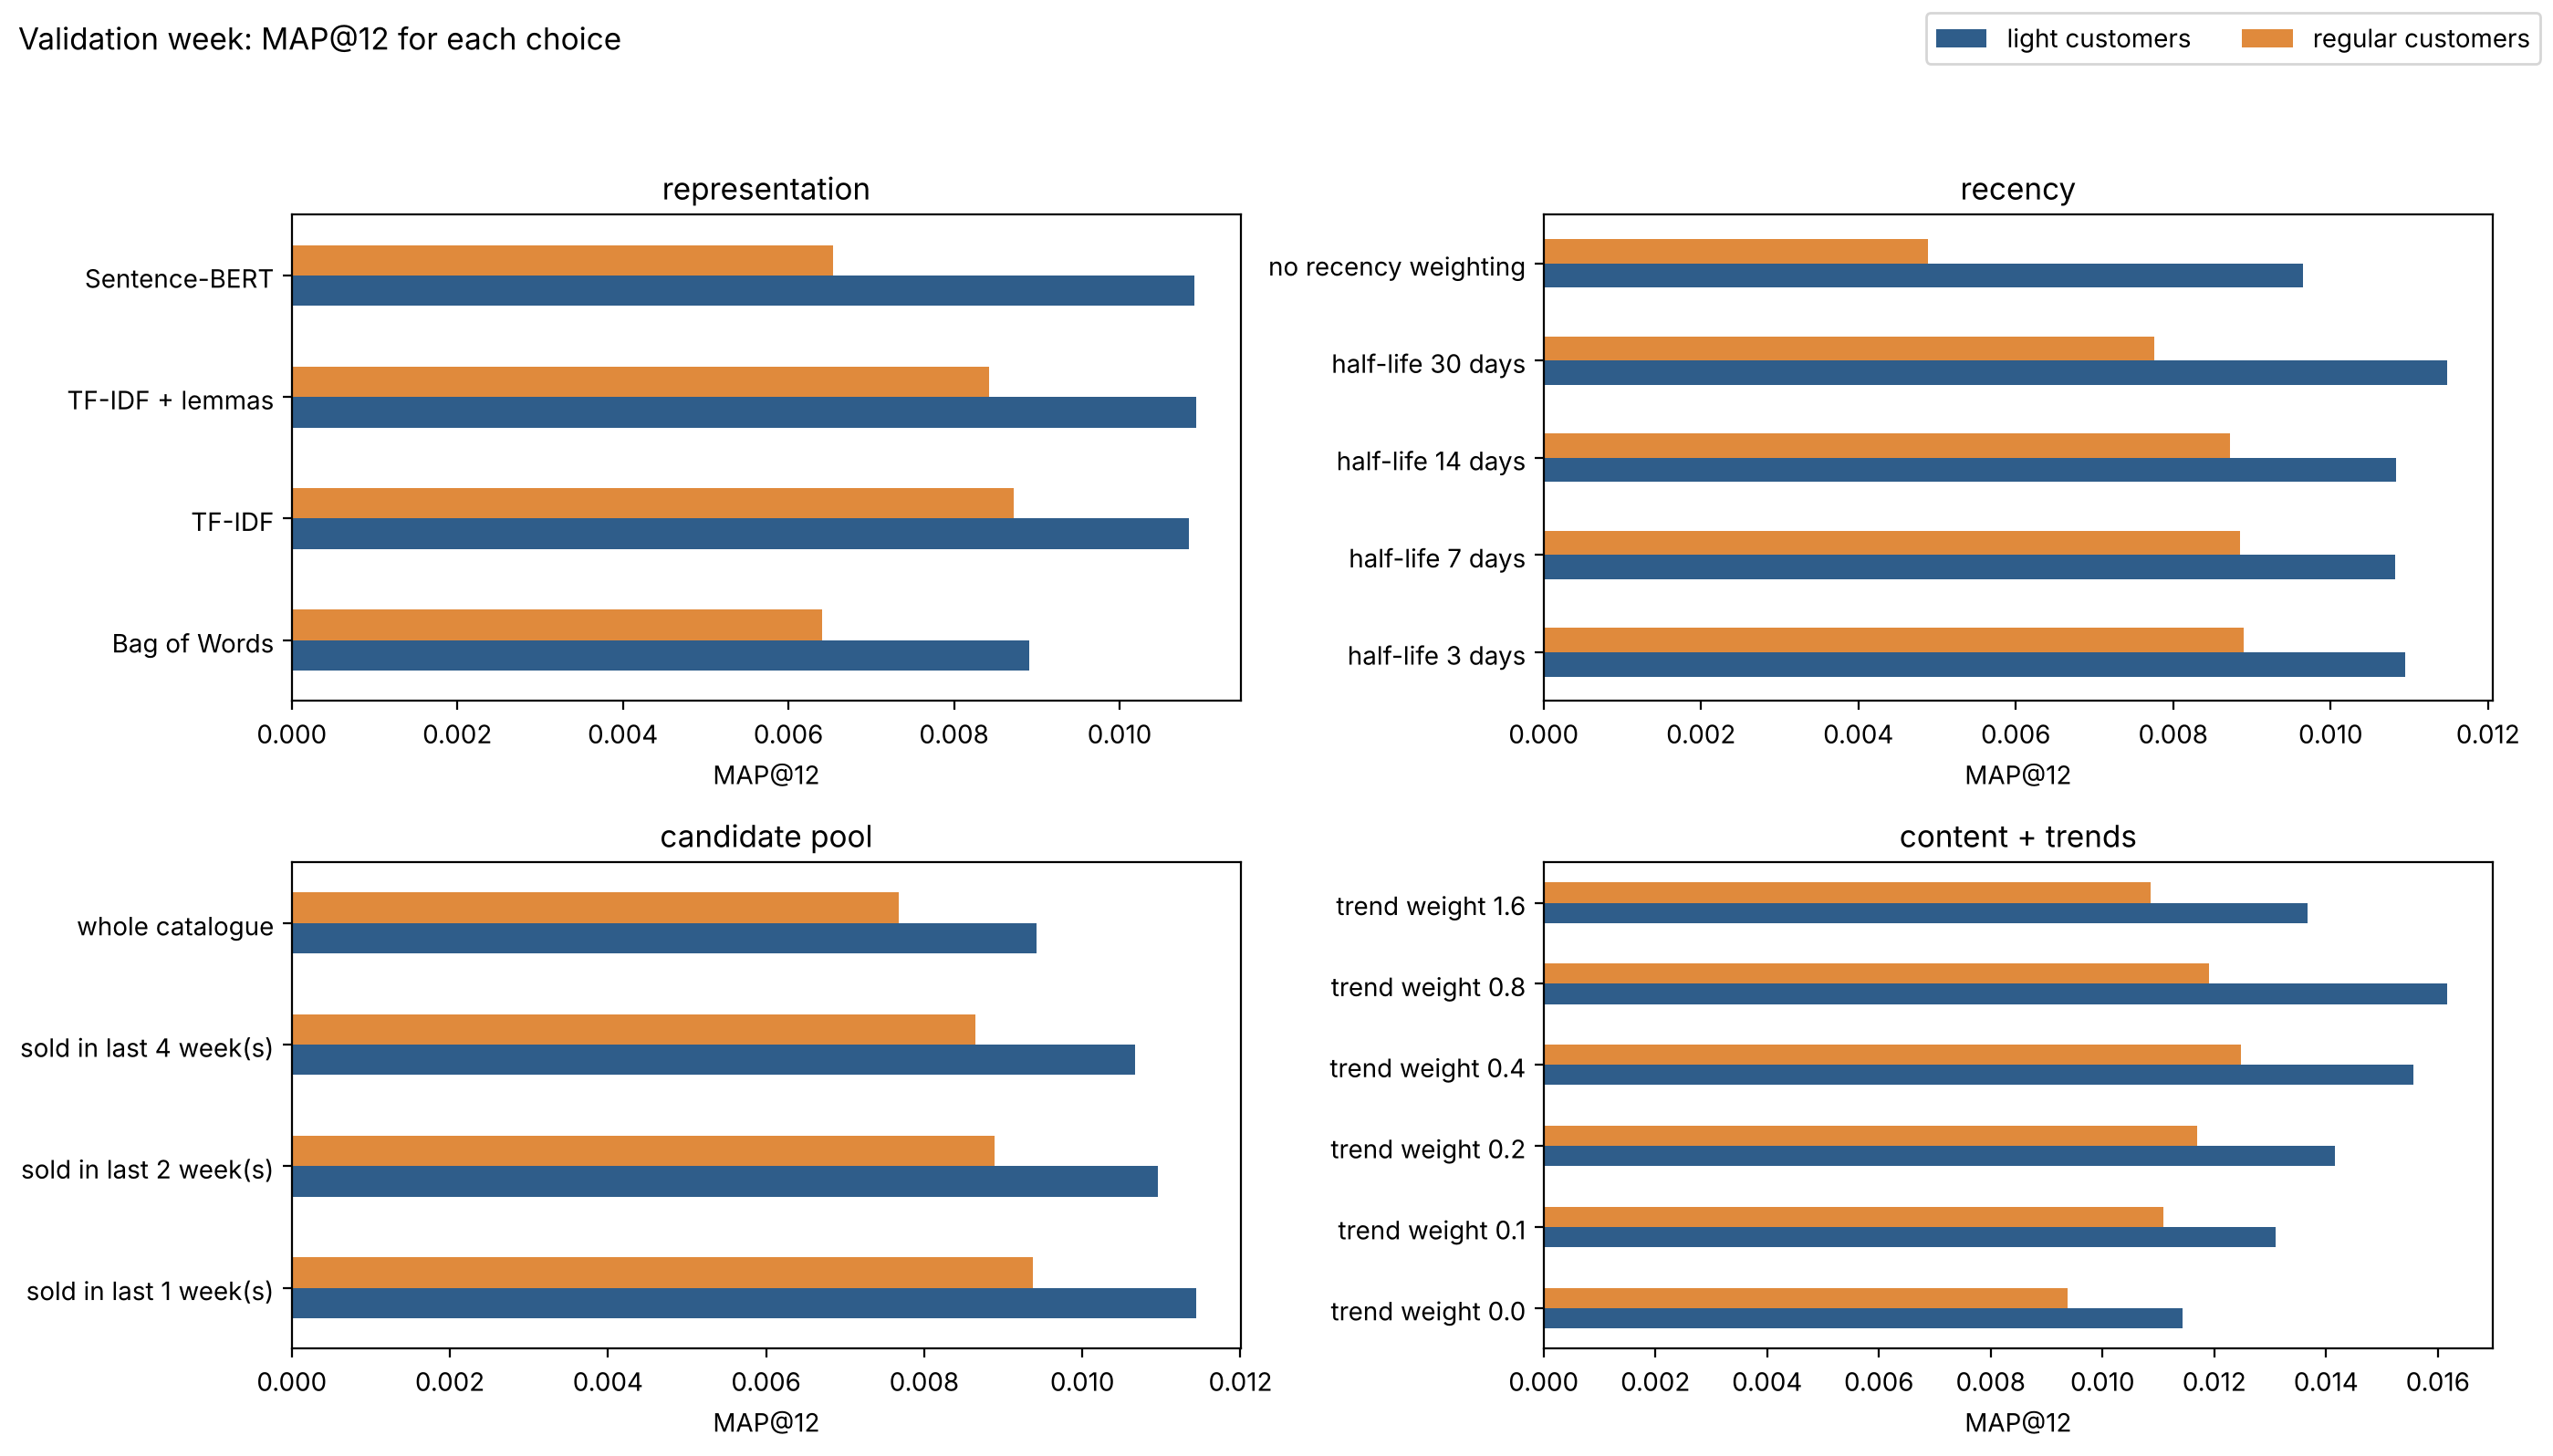

In [15]:
val_log = pd.DataFrame(runs)
val_log.to_csv(REPORTS / "m4_validation_runs.csv", index=False)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, step in zip(axes.ravel(), ["representation", "recency", "candidate pool", "content + trends"]):
    d = val_log[val_log["step"] == step].set_index("setting")
    d[["MAP@12 light", "MAP@12 regular"]].plot.barh(ax=ax, legend=False, color=["#2F5D8A", "#E08A3C"])
    ax.set_title(step); ax.set_ylabel(""); ax.set_xlabel("MAP@12")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, ["light customers", "regular customers"], loc="upper right", ncol=2)
fig.suptitle("Validation week: MAP@12 for each choice", x=0.01, ha="left", y=0.99)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(FIG_DIR / "m4_validation.png", dpi=150, bbox_inches="tight"); plt.show()

**Chosen settings:** TF-IDF on name + attributes + description, 3-day half-life, candidates sold in the last week, trend weight 0.4, re-buying allowed. Every one of these was picked on the validation week; the test week below has not been looked at yet.

## 5. Test week: content against the team's other models

All models are fitted on the full 12 training weeks and scored once on the test week (16 to 22 September 2020) with `evaluate()`. The comparison set:

- **Trending now** and **Trending in age band**: Member 2, two-week window (Member 2's validated choice).
- **Buy again**: Member 2, topped up with the new-customer path.
- **ALS**: Member 3's selected setting (64 factors, regularisation 0.01).
- **Content** and **Content + trends**: this notebook, with the settings chosen in section 4.
- **Content + trends, new-to-you only**: the same model with re-buys switched off, the like-for-like comparison with ALS.

Both content models use Member 2's new-customer path for customers without purchases, so their "new" row matches "Trending in age band" exactly. That's deliberate: the content model only claims the customers it can actually personalise.

In [16]:
final_params = dict(recency_half_life_days=HALF_LIFE, candidate_weeks=POOL_WEEKS,
                    exclude_purchased=EXCLUDE, **rep_params)
fallback = NewCustomerRecommender(weeks=TREND_WEEKS)
models = {
    "Trending now": PopularityRecommender(weeks=TREND_WEEKS),
    "Trending in age band": AgeBandPopularityRecommender(weeks=TREND_WEEKS),
    "Buy again": BuyAgainRecommender(fallback=NewCustomerRecommender(weeks=TREND_WEEKS)),
    "ALS (Member 3)": ALSRecommender(factors=64, regularization=0.01, iterations=15),
    "Content": ContentBasedRecommender(fallback=fallback, **final_params),
    "Content + trends": ContentBasedRecommender(fallback=NewCustomerRecommender(weeks=TREND_WEEKS),
                                                popularity_weight=TREND_WEIGHT, **final_params),
    "Content + trends, new-to-you only": ContentBasedRecommender(
        fallback=NewCustomerRecommender(weeks=TREND_WEEKS), popularity_weight=TREND_WEIGHT,
        **{**final_params, "exclude_purchased": True}),
}
article_info = articles[["article_id", "product_group_name"]]
rows, preds, timing = [], {}, {}
for name, m in models.items():
    t0 = time.time()
    m.fit(train, articles, customers)
    preds[name] = m.recommend_all(list(test_customers))
    res = evaluate(m, test, segments=segments, train=train, articles=article_info)
    timing[name] = time.time() - t0
    rows.append(res.reset_index().assign(model=name))
results = pd.concat(rows, ignore_index=True)
results.to_csv(REPORTS / "m4_content_results.csv", index=False)
print({k: f"{v:.0f}s" for k, v in timing.items()})
results.set_index(["group", "model"]).loc[["all", "new", "light", "regular"],
    ["n_customers", "MAP@12", "Recall@12", "NDCG@12", "HitRate@12"]]

{'Trending now': '7s', 'Trending in age band': '11s', 'Buy again': '39s', 'ALS (Member 3)': '88s', 'Content': '134s', 'Content + trends': '132s', 'Content + trends, new-to-you only': '132s'}


n_customers  MAP@12  Recall@12  \
group   model                                                               
all     Trending now                             68984  0.0072     0.0250   
        Trending in age band                     68984  0.0094     0.0291   
        Buy again                                68984  0.0232     0.0536   
        ALS (Member 3)                           68984  0.0075     0.0205   
        Content                                  68984  0.0236     0.0467   
        Content + trends                         68984  0.0260     0.0530   
        Content + trends, new-to-you only        68984  0.0119     0.0304   
new     Trending now                             19765  0.0072     0.0258   
        Trending in age band                     19765  0.0092     0.0307   
        Buy again                                19765  0.0092     0.0307   
        ALS (Member 3)                           19765  0.0045     0.0147   
        Content                                  19765  0.0092     0.0307   
        Content + trends                         19765  0.0092     0.0307   
        Content + trends, new-to-you only        19765  0.0092     0.0307   
light   Trending now                             16051  0.0080     0.0274   
        Trending in age band                     16051  0.0105     0.0318   
        Buy again                                16051  0.0346     0.0623   
        ALS (Member 3)                           16051  0.0108     0.0256   
        Content                                  16051  0.0332     0.0545   
        Content + trends                         16051  0.0368     0.0633   
        Content + trends, new-to-you only        16051  0.0140     0.0312   
regular Trending now                             33168  0.0068     0.0233   
        Trending in age band                     33168  0.0090     0.0267   
        Buy again                                33168  0.0261     0.0630   
        ALS (Member 3)                           33168  0.0077     0.0215   
        Content                                  33168  0.0275     0.0524   
        Content + trends                         33168  0.0308     0.0613   
        Content + trends, new-to-you only        33168  0.0125     0.0299   

                                           NDCG@12  HitRate@12  
group   model                                                   
all     Trending now                        0.0140      0.0613  
        Trending in age band                0.0173      0.0696  
        Buy again                           0.0352      0.1037  
        ALS (Member 3)                      0.0132      0.0493  
        Content                             0.0334      0.0860  
        Content + trends                    0.0375      0.0993  
        Content + trends, new-to-you only   0.0199      0.0686  
new     Trending now                        0.0142      0.0620  
        Trending in age band                0.0176      0.0732  
        Buy again                           0.0176      0.0732  
        ALS (Member 3)                      0.0092      0.0419  
        Content                             0.0176      0.0732  
        Content + trends                    0.0176      0.0732  
        Content + trends, new-to-you only   0.0176      0.0732  
light   Trending now                        0.0151      0.0599  
        Trending in age band                0.0184      0.0672  
        Buy again                           0.0456      0.1054  
        ALS (Member 3)                      0.0168      0.0479  
        Content                             0.0415      0.0791  
        Content + trends                    0.0471      0.0947  
        Content + trends, new-to-you only   0.0210      0.0576  
regular Trending now                        0.0135      0.0615  
        Trending in age band                0.0165      0.0685  
        Buy again                           0.0407      0.1210  
        ALS (Member 3)                    

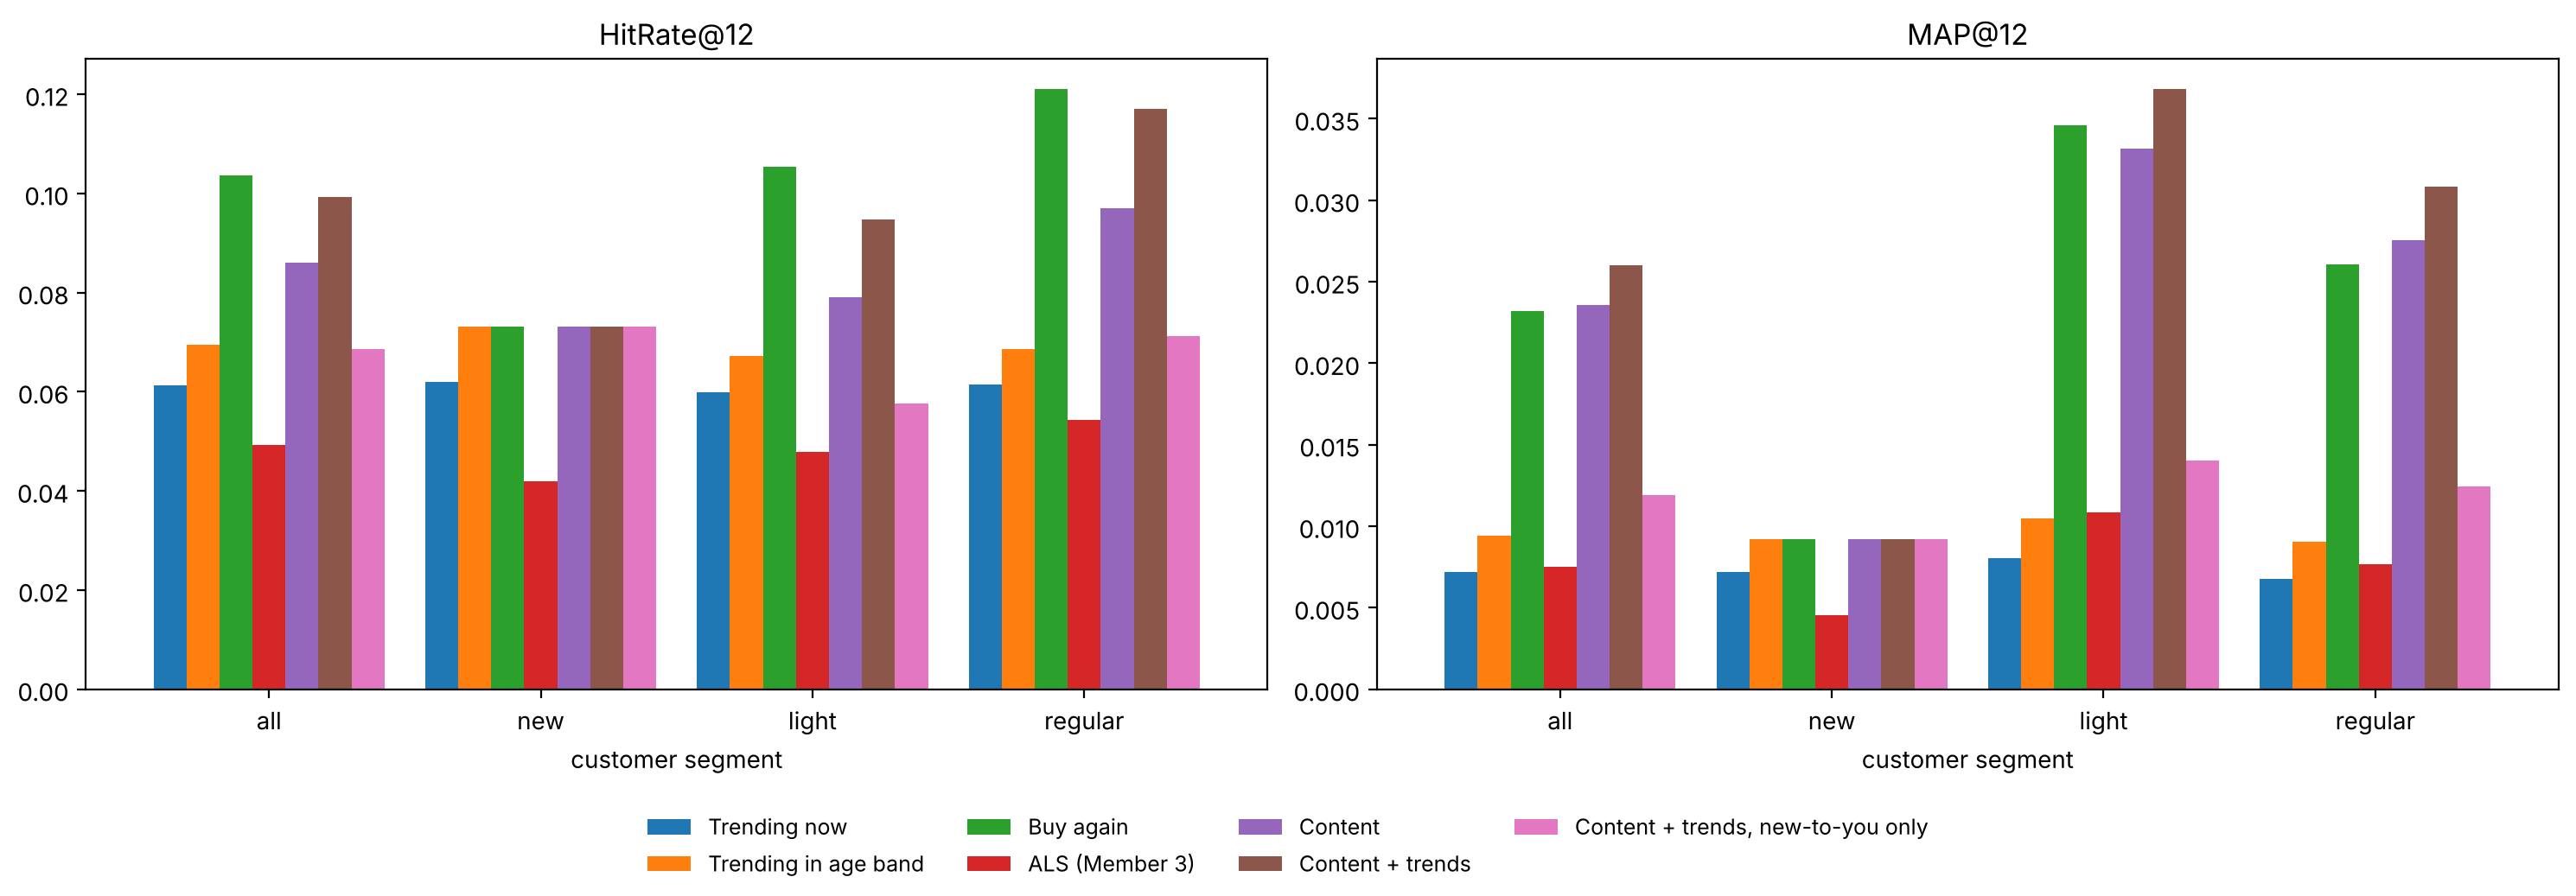

,hit rate vs trending (all),hit rate vs trending (light),hit rate vs trending (regular)
model,,,
Trending now,1.0000,1.0000,1.0000
Trending in age band,1.1351,1.1216,1.1148
Buy again,1.6920,1.7588,1.9686
ALS (Member 3),0.8046,0.7994,0.8847
Content,1.4031,1.3191,1.5772
Content + trends,1.6205,1.5800,1.9049
"Content + trends, new-to-you only",1.1202,0.9605,1.1599


In [17]:
order = list(models)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, metric in zip(axes, ["HitRate@12", "MAP@12"]):
    (results.pivot(index="group", columns="model", values=metric)
            .loc[["all", "new", "light", "regular"], order].plot.bar(ax=ax, rot=0, width=0.85, legend=False))
    ax.set_title(metric); ax.set_xlabel("customer segment")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.savefig(FIG_DIR / "m4_test_by_segment.png", dpi=150); plt.show()

head = results.set_index(["group", "model"])
gain = pd.DataFrame({
    seg: head.loc[seg, "HitRate@12"] / head.loc[(seg, "Trending now"), "HitRate@12"]
    for seg in ["all", "light", "regular"]
}).loc[order]
gain.columns = [f"hit rate vs trending ({c})" for c in gain.columns]
gain

**Reading this.** The validation results hold up on the test week.

- **Content + trends ranks better than anything else the team has built.** MAP@12 0.026 overall, against 0.023 for "buy again", 0.009 for trending in age band and 0.008 for ALS. It reaches 1.6 times as many customers as "trending now" (9.9% of test customers buy at least one recommended product, against 6.1%).
- **For light customers specifically**, the segment Member 5 routes to this model, the hit rate goes from 6.0% with "trending now" to 9.5%, and MAP@12 from 0.008 to 0.037.
- **"Buy again" is still the one to respect.** It reaches slightly more customers (10.4% against 9.9%), while content + trends puts the right product higher in the list (higher MAP and NDCG). Section 5.1 shows why they're close: they overlap.
- **ALS is weaker than trending on this week**, as Member 3 found. Part of that is that it never repeats a purchase, which section 4.5 showed is where a lot of the easy hits are.

New customers get the same list in every content row (Member 2's path), which is why that row matches "Trending in age band" exactly.

### 5.1 Where do the hits come from: re-buys or new products?

Re-buys and discovery are different jobs. A re-buy is easy to predict but adds little the customer wouldn't have found anyway; a new product is harder to predict and is where a recommender earns its keep. For every customer with history, I check whether the list hit something they had bought before, something new to them, or both.

In [18]:
past = train[train["customer_id"].isin(test_customers)].groupby("customer_id")["article_id"].agg(set)
actual = test.groupby("customer_id")["article_id"].agg(set)
warm = [c for c in test_customers if segments[c] != "new"]
split = {}
for name in ["Buy again", "ALS (Member 3)", "Content + trends", "Content + trends, new-to-you only"]:
    rebuy = new = 0
    for c in warm:
        hits = set(preds[name][c]) & actual[c]
        rebuy += bool(hits & past[c]); new += bool(hits - past[c])
    split[name] = {"hit on a re-buy (%)": 100 * rebuy / len(warm),
                   "hit on something new to them (%)": 100 * new / len(warm)}
pd.DataFrame(split).T.round(2)

,hit on a re-buy (%),hit on something new to them (%)
Buy again,8.7400,2.9400
ALS (Member 3),0.0000,5.2300
Content + trends,5.9800,5.9100
"Content + trends, new-to-you only",0.0000,6.6800


**Reading this.** The two kinds of hit split cleanly by model:

- **"Buy again"** gets almost all of its hits from re-buys (8.7% of customers with history), and only 2.9% find something new in its list, usually from the trending top-up.
- **Content + trends** is balanced: 6.0% re-buy hits and 5.9% new-product hits. It is the only model that does both jobs reasonably well in one list.
- **For discovery alone**, the new-to-you version is the best model the team has: 6.7% of customers with history buy a product they'd never bought before from it, against 5.2% for ALS, 28% more.

So the honest summary is that content does two things. It finds the basics people re-buy almost as well as "buy again", and it finds *new* products for them better than collaborative filtering. For the hybrid this suggests a split list: a few re-buy slots, and the rest from the new-to-you content model.

## 6. Light customers: does a single purchase help?

Light customers bought 1 to 4 items in twelve weeks. Here they're split by exactly how many, to see how fast each model improves as we learn about someone.

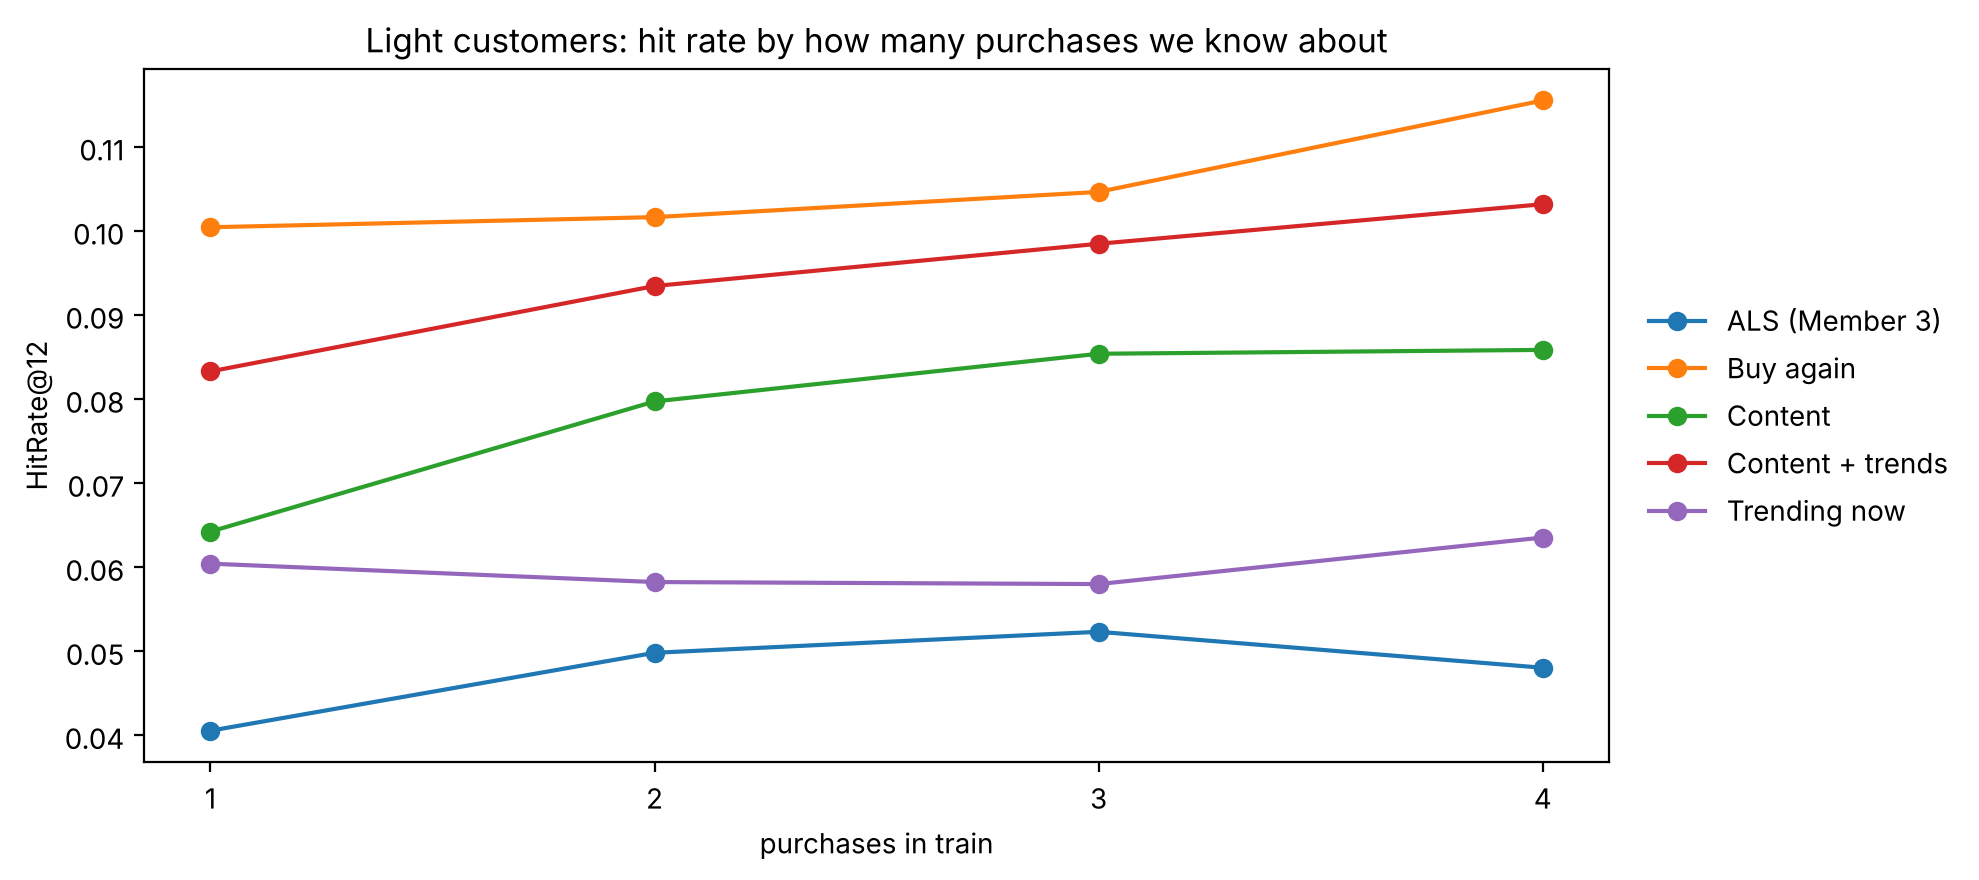

model,ALS (Member 3),Buy again,Content,Content + trends,Trending now,customers
purchases in train,,,,,,
1,0.0406,0.1004,0.0642,0.0833,0.0604,3674
2,0.0498,0.1016,0.0797,0.0934,0.0582,4516
3,0.0523,0.1046,0.0854,0.0985,0.0580,4052
4,0.0480,0.1155,0.0858,0.1032,0.0635,3809


In [19]:
light_ids = segments.index[segments == "light"]
light_test = test[test["customer_id"].isin(light_ids)]
n_bought = train[train["customer_id"].isin(light_ids)].groupby("customer_id").size()
by_history = []
for n in sorted(n_bought.unique()):
    ids = n_bought.index[n_bought == n]
    sub = light_test[light_test["customer_id"].isin(ids)]
    for name in ["Trending now", "Buy again", "ALS (Member 3)", "Content", "Content + trends"]:
        r = evaluate(models[name], sub)
        by_history.append({"purchases in train": n, "model": name, "customers": len(ids),
                           "HitRate@12": r.loc["all", "HitRate@12"]})
by_history = pd.DataFrame(by_history)
ax = by_history.pivot(index="purchases in train", columns="model", values="HitRate@12").plot(
    marker="o", figsize=(10, 4.5))
ax.set_title("Light customers: hit rate by how many purchases we know about")
ax.set_ylabel("HitRate@12"); ax.set_xticks([1, 2, 3, 4])
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False); plt.tight_layout()
plt.savefig(FIG_DIR / "m4_light_by_history.png", dpi=150); plt.show()
by_history.pivot(index="purchases in train", columns="model", values="HitRate@12").assign(
    customers=by_history.groupby("purchases in train")["customers"].first())

**Reading this.** One purchase is already enough for content to beat "trending now" (8.3% against 6.0%), and every extra purchase adds about a point, up to 10.3% at four. ALS stays under trending throughout, since one or two purchases don't place a customer anywhere useful in its factor space. This is the case for routing light customers to content: it's the model that turns a first purchase into a better second visit. "Buy again" is a little higher at every step, so in production I'd show both rows, not one or the other.

## 7. Brand-new products

Launches are a blind spot for everything built so far. "Trending now" can't rank a product with no sales, CF has no learned vector for it, and "buy again" never shows anything new. A content model only needs the description, which exists on day one.

**Assumption, stated plainly.** The model needs to know which products are launching. I use the articles that first sell in the test week. In practice the merchandising team knows next week's launches in advance, so this is realistic, but it does use the test week to define the launch list (never to see who bought what).

### 7.1 A "new in for you" row

Each customer gets 12 launches. The test is the test week restricted to launch purchases, so the question is "among launches, did we put the ones you bought in front of you?" Two baselines:

- **Random launches**: today's approach, applied to new products.
- **Launches in best-selling types**: no model, no personal data. Rank launches by how well their product type sold last week. This is what a merchandiser would do by hand, and the real bar to clear.

Customers with no purchase history get the launches closest to "what's selling now" (the content profile of last week's sales).

In [20]:
for name in ["ALS (Member 3)", "Trending in age band", "Buy again"]:
    models[name] = None          # scores and lists are kept; the fitted models are not needed any more
gc.collect()

launch_test = test[test["article_id"].isin(launches)]
launch_buyers = pd.Series(launch_test["customer_id"].unique())
launch_segments = segments.loc[launch_buyers]
print(f"{len(launch_buyers):,} test customers bought at least one launch")
print(launch_segments.value_counts().to_string())
buyers_per_launch = launch_test.groupby("article_id")["customer_id"].nunique().sort_values(ascending=False)
print(f"buyers per launch: median {buyers_per_launch.median():.0f}; the 12 biggest launches have "
      f"{buyers_per_launch.iloc[:12].sum() / buyers_per_launch.sum():.0%} of all launch buyers")

launch_info = articles[articles["article_id"].isin(launches)]
launch_models = {
    "Random launches": RandomRecommender(seed=SEED),
    "Launches in best-selling types": AttributePopularityRecommender(launches, weeks=1),
    "Content: launches like your purchases": ContentBasedRecommender(
        candidate_items=launches, only_candidate_items=True, popularity_weight=0.0,
        **{k: v for k, v in final_params.items() if k != "candidate_weeks"}),
}
launch_rows = []
for name, m in launch_models.items():
    m.fit(train, launch_info if name.startswith("Random") else articles, customers)
    r = evaluate(m, launch_test, segments=launch_segments)
    launch_rows.append(r.reset_index().assign(model=name))
launch_results = pd.concat(launch_rows, ignore_index=True)
launch_results.to_csv(REPORTS / "m4_launch_row_results.csv", index=False)
launch_results.set_index(["group", "model"]).loc[["all", "new", "light", "regular"],
    ["n_customers", "MAP@12", "Recall@12", "HitRate@12"]]

6,134 test customers bought at least one launch
segment
regular    3388
new        1581
light      1165
buyers per launch: median 1; the 12 biggest launches have 29% of all launch buyers


n_customers  MAP@12  Recall@12  \
group   model                                                                   
all     Random launches                               6134  0.0040     0.0131   
        Launches in best-selling types                6134  0.0028     0.0066   
        Content: launches like your purchases         6134  0.0244     0.0620   
new     Random launches                               1581  0.0041     0.0127   
        Launches in best-selling types                1581  0.0024     0.0061   
        Content: launches like your purchases         1581  0.0110     0.0343   
light   Random launches                               1165  0.0047     0.0145   
        Launches in best-selling types                1165  0.0013     0.0044   
        Content: launches like your purchases         1165  0.0259     0.0673   
regular Random launches                               3388  0.0037     0.0129   
        Launches in best-selling types                3388  0.0036     0.0076   
        Content: launches like your purchases         3388  0.0301     0.0731   

                                               HitRate@12  
group   model                                              
all     Random launches                            0.0189  
        Launches in best-selling types             0.0098  
        Content: launches like your purchases      0.0706  
new     Random launches                            0.0183  
        Launches in best-selling types             0.0089  
        Content: launches like your purchases      0.0392  
light   Random launches                            0.0206  
        Launches in best-selling types             0.0060  
        Content: launches like your purchases      0.0738  
regular Random launches                            0.0186  
        Launches in best-selling types             0.0115  
        Content: launches like your purchases      0.0841

**Reading this.** The personal launch row works: 7.1% of launch buyers had one of their launches in their 12 slots, against 1.9% with random launches, so **3.7 times as many**. MAP@12 goes from 0.004 to 0.024. It helps most for regular customers (8.4%), where the profile is richest, but even customers with no history do twice as well as random (3.9% against 1.8%) just from "launches that look like what's selling now".

The merchandiser rule does *worse than random* (1.0%), which surprised me. The reason is in how launches sell. Demand is extremely concentrated: the 12 biggest launches account for 29% of all launch buyers, and the median launch had a single buyer all week. Knowing that sweaters sell tells you nothing about *which* of the dozens of new sweaters will be the hit. Matching a launch to people who already buy that kind of product does tell you something.

About half the launches (48%) are new colours or versions of products that were already selling, which probably makes this easier: a customer who bought the black version is an obvious candidate for the new beige one. The other 52% are product codes that hadn't sold at all in the twelve weeks.

### 7.2 Launch audiences: who should hear about a new product?

The same model, read the other way round. For each launch, rank every customer with purchase history by how well their profile matches the product, and pick the top 1,000, the size of a targeted email or app push. A hit is a targeted customer who bought that launch in the test week.

Baselines: 1,000 random customers (the expected number of buyers is computable exactly) and the 1,000 most active customers of the last four weeks, who are likelier to buy *anything*. That second one is the honest comparison, since heavy shoppers inflate any targeting rule.

In [21]:
content_model = models["Content"]
known = pd.Index(content_model.customer_index_)
buyers_by_item = (launch_test[launch_test["customer_id"].isin(known)]
                  .groupby("article_id")["customer_id"].agg(set))
items = buyers_by_item.index.tolist()
N = 1000
recent_activity = train[train["t_dat"] > train["t_dat"].max() - pd.Timedelta(weeks=4)]
active = recent_activity.groupby("customer_id").size().sort_values(ascending=False)

t0 = time.time()
aud_all = content_model.audience(items, n=N)
aud_active = content_model.audience(items, n=N, universe=active.index)
aud_top5k = content_model.audience(items, n=N, universe=active.index[:5_000])
aud_top20k = content_model.audience(items, n=N, universe=active.index[:20_000])
print(f"audiences for {len(items)} launches in {time.time() - t0:.0f}s")

most_active = set(active.index[:N])
tot_buyers = sum(len(b) for b in buyers_by_item)
rows = {
    "Random customers (expected)": tot_buyers * N / len(known),
    "Most active customers": sum(len(b & most_active) for b in buyers_by_item),
    "Content match, all customers": sum(len(b & set(aud_all[i])) for i, b in buyers_by_item.items()),
    "Content match, active in last 4 weeks": sum(len(b & set(aud_active[i]))
                                                 for i, b in buyers_by_item.items()),
    "Content match within the 20,000 most active": sum(len(b & set(aud_top20k[i]))
                                                       for i, b in buyers_by_item.items()),
    "Content match within the 5,000 most active": sum(len(b & set(aud_top5k[i]))
                                                      for i, b in buyers_by_item.items()),
}
audience_table = pd.DataFrame({"buyers reached": rows})
audience_table["share of launch buyers reached"] = audience_table["buyers reached"] / tot_buyers
audience_table["lift vs random"] = audience_table["buyers reached"] / rows["Random customers (expected)"]
print(f"{len(items)} launches, {tot_buyers:,} (launch, buyer) pairs among {len(known):,} known customers; "
      f"each campaign targets {N:,} customers ({N / len(known):.2%} of them)")
audience_table

audiences for 784 launches in 48s
784 launches, 6,429 (launch, buyer) pairs among 505,310 known customers; each campaign targets 1,000 customers (0.20% of them)


,buyers reached,share of launch buyers reached,lift vs random
Random customers (expected),12.7229,0.0020,1.0000
Most active customers,176.0000,0.0274,13.8333
"Content match, all customers",133.0000,0.0207,10.4536
"Content match, active in last 4 weeks",143.0000,0.0222,11.2396
"Content match within the 20,000 most active",194.0000,0.0302,15.2481
"Content match within the 5,000 most active",213.0000,0.0331,16.7415


**Reading this.** Content targeting reaches 10 times more launch buyers than a random mailing (133 against an expected 13), but on its own it loses to the blunt rule "email your 1,000 most active customers" (176). Heavy shoppers buy a bit of everything, including launches.

The two ideas combine well. Taking the 5,000 most active customers and then choosing, for each launch, the 1,000 whose taste matches it best reaches **213 buyers: 21% more than "most active" and 17 times random.** Same campaign size, same cost per message, better aim, and each of those customers gets launches they're likely to care about instead of all of them.

A caveat on scale: 784 launches with buyers, 6,429 launch purchases among half a million known customers. These are small absolute numbers, and a single test week. The lift is large enough that I'd trust its direction, not the exact percentage.

## 8. Diversity and novelty: is it all black T-shirts?

The risk with content is obvious. If someone bought a black T-shirt, the most similar products are other black T-shirts, starting with the same T-shirt in other colours. I measure each list directly, for customers with history:

- distinct product types and colours in the 12 slots,
- the share of slots taken by the list's most common colour,
- how many slots are colour variants of a product already in the list,
- the share of black items.

The customer's own last 12 purchases give the reference. A list that's narrower than what the person actually buys is a filter bubble; one that matches it is just accurate.

To test a fix, one more version of content + trends keeps **one colour per product** (`one_per_product=True`): only the best-scoring variant of each `product_code` makes the list.

In [22]:
known_test = [c for c in test_customers if segments[c] != "new"]
colour = info["colour_group_name"].to_dict(); ptype = info["product_type_name"].to_dict()
pcode = info["product_code"].to_dict(); master = info["perceived_colour_master_name"].to_dict()

def list_profile(lists):
    """Per-list diversity numbers, averaged over customers."""
    out = []
    for items in lists:
        cols = [colour[i] for i in items]; types = [ptype[i] for i in items]
        top_colour_share = pd.Series(cols).value_counts().iloc[0] / len(items)
        out.append({"distinct product types": len(set(types)),
                    "distinct colours": len(set(cols)),
                    "share of slots in the top colour": top_colour_share,
                    "colour variants of the same product": len(items) - len({pcode[i] for i in items}),
                    "share black": np.mean([master[i] == "Black" for i in items])})
    return pd.DataFrame(out).mean()

own = (train[train["customer_id"].isin(known_test)].sort_values("t_dat")
       .groupby("customer_id")["article_id"].agg(lambda s: list(dict.fromkeys(s))[-12:]))
own = own[own.str.len() >= 5]
div = {"What they bought (last 12, 5+ items)": list_profile(own)}
models["Content + trends, one colour per product"] = ContentBasedRecommender(
    fallback=NewCustomerRecommender(weeks=TREND_WEEKS), one_per_product=True,
    popularity_weight=TREND_WEIGHT, **final_params).fit(train, articles, customers)
preds["Content + trends, one colour per product"] = models["Content + trends, one colour per product"].recommend_all(
    list(test_customers))
for name in ["Trending now", "Buy again", "ALS (Member 3)", "Content", "Content + trends",
             "Content + trends, new-to-you only", "Content + trends, one colour per product"]:
    div[name] = list_profile([preds[name][c] for c in known_test])
diversity_table = pd.DataFrame(div).T
diversity_table

,distinct product types,distinct colours,share of slots in the top colour,colour variants of the same product,share black
"What they bought (last 12, 5+ items)",5.9258,5.7782,0.3872,0.7828,0.3237
Trending now,6.0000,4.0000,0.5833,1.0000,0.5833
Buy again,7.0172,6.0232,0.4230,0.9309,0.4047
ALS (Member 3),4.3506,5.5950,0.4543,3.2449,0.4086
Content,1.9743,5.9922,0.4194,6.2762,0.3081
Content + trends,2.2129,5.8720,0.4415,5.7352,0.3651
"Content + trends, new-to-you only",2.2266,5.9576,0.4385,5.1449,0.3664
"Content + trends, one colour per product",2.9752,4.2118,0.5953,0.0039,0.4868


In [23]:
r = evaluate(models["Content + trends, one colour per product"], test, segments=segments, train=train,
             articles=article_info)
results = pd.concat([results, r.reset_index().assign(model="Content + trends, one colour per product")],
                    ignore_index=True)
results.to_csv(REPORTS / "m4_content_results.csv", index=False)
beyond = (results[results["group"] == "all"].set_index("model")
          [["MAP@12", "HitRate@12", "coverage", "gini", "diversity", "novelty"]])
beyond

,MAP@12,HitRate@12,coverage,gini,diversity,novelty
model,,,,,,
Trending now,0.0072,0.0613,0.0001,0.0000,0.2500,10.5660
Trending in age band,0.0094,0.0696,0.0004,0.4227,0.2440,10.8643
Buy again,0.0232,0.1037,0.2445,0.8667,0.2888,11.9107
ALS (Member 3),0.0075,0.0493,0.0330,0.7779,0.2725,11.1926
Content,0.0236,0.0860,0.1699,0.7194,0.1576,13.3041
Content + trends,0.0260,0.0993,0.1504,0.8295,0.1645,12.5539
"Content + trends, new-to-you only",0.0119,0.0686,0.1395,0.8379,0.1634,12.5839
"Content + trends, one colour per product",0.0226,0.0898,0.1213,0.8738,0.1827,12.4574


**Reading this.** "All black T-shirts" is the wrong worry, and the real problem is worse.

- **Colour is fine.** Content lists hold about 6 colours out of 12 slots, the same as what customers actually buy, and only 37% black against 58% in "trending now" (which happens to be full of black basics).
- **Variety of products is not.** Content + trends shows on average **5.7 colour variants** of products already in the list, so a typical list is five or six products in two colours each. It covers only 2.2 product types, while the same customers bought 5.9 types over their last 12 purchases. The "same T-shirt in five colours" effect from section 3.1 shows up directly in the lists, and the evaluator's product-group diversity agrees (0.16, the lowest of any model).
- **Keeping one colour per product fixes the duplicates but costs accuracy.** Variants drop to almost zero and product types rise to 3.0, but MAP@12 falls from 0.026 to 0.023 and the hit rate from 9.9% to 9.0%. Some customers really do buy the same piece in another colour. The list also gets *darker* (49% black), because the slots freed up go to the next most similar items, and those tend to be black basics.
- **Beyond accuracy it's not all bad.** Content + trends shows 15% of the catalogue (trending shows 12 items to everyone) and recommends less obvious products: novelty 12.6 bits against 10.6 for trending and 11.9 for buy again.

My recommendation for the hybrid: keep the variants, but cap them, for example two colours per product per list, and let the slots that frees go to a different product type. That's a business choice between short-term clicks and a shop that feels narrower than it is, so I'd test it in Member 5's A/B plan rather than decide it here.

## 9. Why this product? Explanations for one light customer

Content recommendations are easy to explain, which matters for trust and for the CEO demo. `explain()` finds the past purchases most similar to a recommended product, giving a "because you bought..." line. Below is a light customer the content + trends model got right and "trending now" missed.

In [24]:
cm = models["Content + trends"]
light_hits = [c for c in light_ids
              if (set(preds["Content + trends"][c]) & actual[c]) - past[c]
              and not set(preds["Trending now"][c]) & actual[c]]
richer = [c for c in light_hits if n_bought[c] >= 3]       # an example with a bit of history
print(f"light customers where Content + trends found something new to them "
      f"that Trending now missed: {len(light_hits):,}")
cid = (richer or light_hits)[0]
bought_next = set(test.loc[test["customer_id"] == cid, "article_id"])
cols = ["prod_name", "product_type_name", "colour_group_name"]

bought_on = (train[train["customer_id"] == cid].groupby("article_id")["t_dat"].max()
             .dt.strftime("%d %b").rename("last bought"))
hist = (cm.history(cid).merge(info[cols], left_on="article_id", right_index=True)
          .join(bought_on, on="article_id"))
hist["share of profile"] = (hist["weight"] / hist["weight"].sum()).round(3)
print("\nWhat this customer bought (weight: how much it counts on 15 Sep, 3-day half-life):")
display(hist)
recs = pd.DataFrame({"article_id": preds["Content + trends"][cid]}).merge(
    info[cols], left_on="article_id", right_index=True)
recs["bought in test week"] = recs["article_id"].isin(bought_next)
print("What Content + trends shows them:")
display(recs)
hit = recs.loc[recs["bought in test week"] & ~recs["article_id"].isin(past[cid]), "article_id"].iloc[0]
why = cm.explain(cid, hit, top=2).merge(info[["prod_name"]], left_on="article_id", right_index=True)
print(f'"{info.loc[hit, "prod_name"]}" was recommended because you bought:')
display(why)

light customers where Content + trends found something new to them that Trending now missed: 771

What this customer bought (weight: how much it counts on 15 Sep, 3-day half-life):


,article_id,weight,prod_name,product_type_name,colour_group_name,last bought,share of profile
0,865240001,0.0787,Flirty Silja earcuff,Other accessories,Gold,04 Sep,0.3330
1,915529001,0.0787,Liliana,Sweater,Beige,04 Sep,0.3330
2,916598001,0.0787,Renee PU,Blouse,Black,04 Sep,0.3330


What Content + trends shows them:


,article_id,prod_name,product_type_name,colour_group_name,bought in test week
0,915529003,Liliana,Sweater,Black,False
1,915529001,Liliana,Sweater,Beige,False
2,915529005,Liliana,Sweater,Beige,False
3,916598001,Renee PU,Blouse,Black,False
4,863646001,Matey,Sweater,Black,True
5,918525001,Frill cable,Sweater,Beige,False
6,920283001,Liliana fluff,Sweater,White,False
7,893141002,Sandy,Sweater,Beige,False
8,863646004,Matey,Sweater,Beige,False
9,911870001,Bama1,Sweater,Black,False


"Matey" was recommended because you bought:


,article_id,weight,similarity,prod_name
0,915529001,0.0787,0.6234,Liliana
1,916598001,0.0787,0.1896,Renee PU


**Reading this.** This customer bought three things on 4 September: an ear cuff, a beige "Liliana" sweater and a black blouse. The model shows the Liliana in other colours, the blouse again, and a run of similar knitwear. They bought the "Matey" sweater, and the explanation is the one a shop assistant would give: it's 0.62 similar to the Liliana they already own.

The example also shows the model's habits from sections 5 and 8 in one list. Four of the 12 slots are Liliana variants or the blouse they already have, and the ear cuff, a third of the profile, leaves no visible trace: knitwear dominates the similarity scores and the trend bonus, so accessories never make it in. A cap on variants and a slot reserved for a second product type would both have helped here.

## 10. What this means for the business

For the CEO, in plain terms:

1. **A product's description is a usable signal from day one.** Turning name, attributes and description into a "taste profile" makes recommendations for anyone who has bought at least once, and it needs no data about the person beyond their purchases.
2. **It's the best model we have for occasional shoppers.** Light customers are 23% of this week's buyers. Content + trends gets 9.5% of them to buy something from their list, against 6.0% for the best-seller list and 4.8% for collaborative filtering.
3. **It's the only model that can sell new products.** Each week about 4% of purchases are products nobody had bought before. A "new in for you" row gets 3.7 times as many of those into the right hands as a random display, and the same model aims launch emails 21% better than "mail the best customers".
4. **The cost is variety, and it's fixable.** Unchecked, a list can show the same product in five colours. Capping colour variants trades a little accuracy for a shop that looks as big as it is; the A/B test should measure both sides.

The table below is the one-line version: share of customers in each segment who bought at least one recommended product.

In [25]:
summary = results.set_index(["group", "model"])["HitRate@12"].unstack(0)[["all", "new", "light", "regular"]]
summary = summary.loc[[m for m in [*order, "Content + trends, one colour per product"] if m in summary.index]]
summary.columns = [f"hit rate: {c}" for c in summary.columns]
summary

,hit rate: all,hit rate: new,hit rate: light,hit rate: regular
model,,,,
Trending now,0.0613,0.0620,0.0599,0.0615
Trending in age band,0.0696,0.0732,0.0672,0.0685
Buy again,0.1037,0.0732,0.1054,0.1210
ALS (Member 3),0.0493,0.0419,0.0479,0.0544
Content,0.0860,0.0732,0.0791,0.0970
Content + trends,0.0993,0.0732,0.0947,0.1171
"Content + trends, new-to-you only",0.0686,0.0732,0.0576,0.0713
"Content + trends, one colour per product",0.0898,0.0732,0.0794,0.1048


## 11. Hand-off, limits and AI use

**For Member 5 (hybrid and business value)**

- **Light customers:** `ContentBasedRecommender(recency_half_life_days=3, candidate_weeks=1, popularity_weight=0.4, exclude_purchased=False, fallback=NewCustomerRecommender(weeks=2))`. It already falls back to Member 2's path for anyone without purchases, so it can be called for any customer ID.
- **Regular customers:** the same model beat ALS on all four accuracy metrics this week, so it's worth including in the weighted blend, not just the light-customer branch.
- **New products:** the same class with `candidate_items=launches, only_candidate_items=True` gives a "new in for you" row; `audience(launches, n=..., universe=...)` gives launch campaign lists.
- **Demo:** `explain(customer_id, article_id)` gives the "because you bought..." line for the light-shopper persona; `similar_items(article_id)` gives "more like this".
- **Numbers:** running the notebook writes `reports/m4_content_results.csv` (test week, every model and segment), `reports/m4_launch_row_results.csv` and `reports/m4_validation_runs.csv` (git ignores CSVs, so they're rebuilt locally); the figures in `reports/figures/m4_*.png` are committed.

**Limits worth saying out loud**

- One test week, in late September. Fashion is seasonal, and a winter week could rank the settings differently.
- "Sold last week" stands in for stock. It's the main reason the candidate pool helps, and a real stock feed would do it properly.
- The launch list comes from the test week (see section 7). That's realistic for a retailer but it is still knowledge the model is handed, not something it learned.
- Content only knows what's written. Two dresses with the same description and a very different look are twins to this model; the product images, which this project didn't use, would be the next signal to add.
- Recommending what people already bought is accurate and also a little lazy. The hybrid should decide how many re-buy slots a list gets on purpose, not let accuracy decide it by default.

**Ethics.** The content model itself only uses what a customer bought and what H&M wrote about its products: no age, no postcode, no inferred traits (age only enters through Member 2's fallback for people with no purchases). That makes it easy to explain to a customer and low-risk from a privacy point of view. The risk it does carry is narrowing, which section 8 measures and the A/B test should keep an eye on.

*Claude was used to help write code and commentary.*